# How much is a movie each tag?

IMDb gives a film up to three genres and no weights, so *Nacho Libre* is "Comedy, Family, Sport" and nothing says
it's mostly a comedy. This notebook scores every tag we have for a film from 0 to 1 and turns the genre scores
into percentages that add up to 100.

The scores come from the MovieLens Tag Genome 2021, which we had already downloaded for its reviews. It rates
1,084 tags per film, from genres ("horror") to themes ("time travel") to opinions ("boring"). Its authors asked
MovieLens users how strongly a tag applies to a film, on a scale of 1 to 5, and trained two models to predict those
answers from user tags, ratings and IMDb review text. We use the mean of the two models' scores (section 6 says why).

Two numbers per film and tag come out of this:

- **Relevance**, 0 to 1: how strongly the tag applies. Each tag is scored on its own.
- **Genre share**: the film's relevance for each of 22 IMDb genres, squared and divided by their sum, so a film's
  shares add up to 1. Section 4 explains the squaring.

`scripts/reviews/tag_shares.py` builds the files this notebook reads. Every number below is printed by a cell.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent   # notebooks -> repo root
FEATURES = REPO / "data" / "raw" / "features"
checks = json.loads((REPO / "analysis" / "tags" / "tag_shares.json").read_text())
relevance = np.load(FEATURES / "tag_relevance.npy")                      # films x tags
tags = pd.read_csv(FEATURES / "tag_relevance_tags.csv", keep_default_na=False)["tag"].tolist()
films = pd.read_csv(FEATURES / "genre_shares.csv")                       # same row order as the matrix
assert films["tconst"].tolist() == pd.read_csv(FEATURES / "tag_relevance_ids.csv")["tconst"].tolist()
GENRES = list(checks["genre_tag"])
share = films[["share_" + g for g in GENRES]].to_numpy()
rel = films[["rel_" + g for g in GENRES]].to_numpy()
imdb = np.array([[g in str(x).split(",") for g in GENRES] for x in films["genres"]])
tag_col = {t: i for i, t in enumerate(tags)}

INK, ACCENT, GREY, LIGHT, RED = "#1F2933", "#1F6F8B", "#8A969C", "#D5E3E8", "#B5482F"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print(f"{relevance.shape[0]:,} films x {relevance.shape[1]:,} tags; shares sum to "
      f"{share.sum(axis=1).min():.3f}-{share.sum(axis=1).max():.3f} per film")

6,530 films x 1,084 tags; shares sum to 1.000-1.000 per film


## 1. Which films have scores

The score files cover only the films of the original Tag Genome, so recent films are missing. Anything that uses
these scores is a study of films up to 2014.

6,530 of 12,673 films with 10,000+ votes have scores
{'100k+': '1,855 of 2,764', '10k-100k': '4,675 of 9,909'}
scored films by year from 2010: {'2010': 221, '2011': 206, '2012': 148, '2013': 111, '2014': 1}


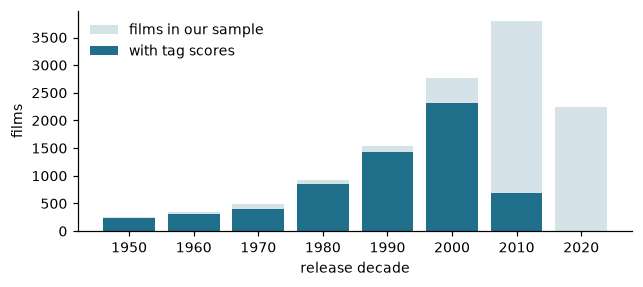

In [2]:
cov = checks["coverage"]
print(f"{cov['scored']:,} of {cov['movies']:,} films with 10,000+ votes have scores")
print({t: f"{v['scored']:,} of {v['movies']:,}" for t, v in cov["by_tier"].items()})
print("scored films by year from 2010:", cov["scored_by_year_from_2010"])
dec = pd.DataFrame(cov["by_decade"]).T
dec = dec[dec.index.astype(int) >= 1950]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.bar(dec.index, dec["movies"], color=LIGHT, label="films in our sample")
ax.bar(dec.index, dec["scored"], color=ACCENT, label="with tag scores")
ax.set_xlabel("release decade"); ax.set_ylabel("films"); ax.legend(frameon=False)
plt.show()

## 2. One film

`show()` draws a film's genre shares next to its ten most distinctive tags: the ones where the film scores
furthest above the typical film. Dark bars are the genres IMDb lists for the film. Change the titles to look up others.

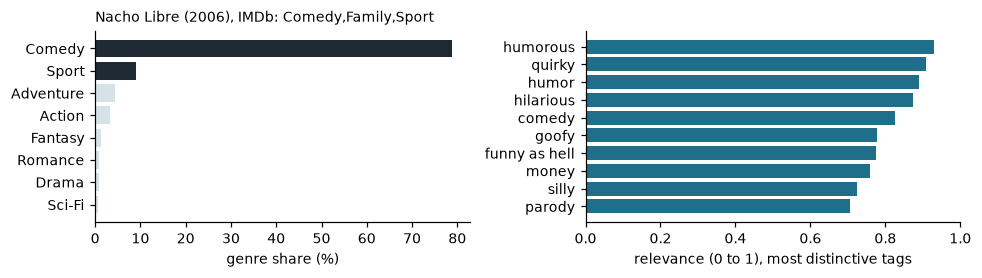

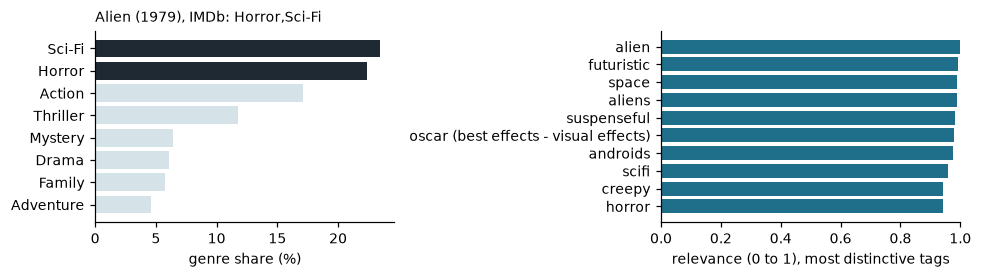

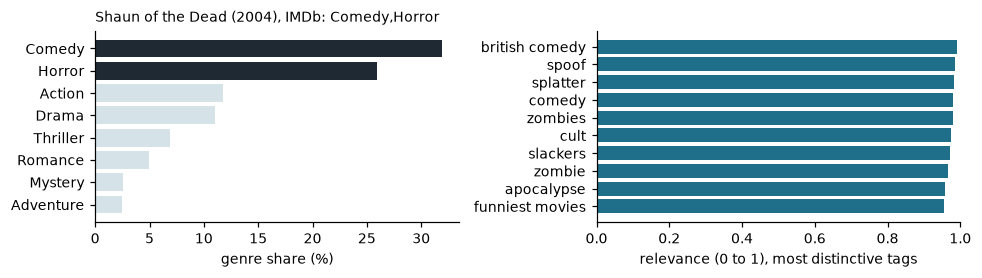

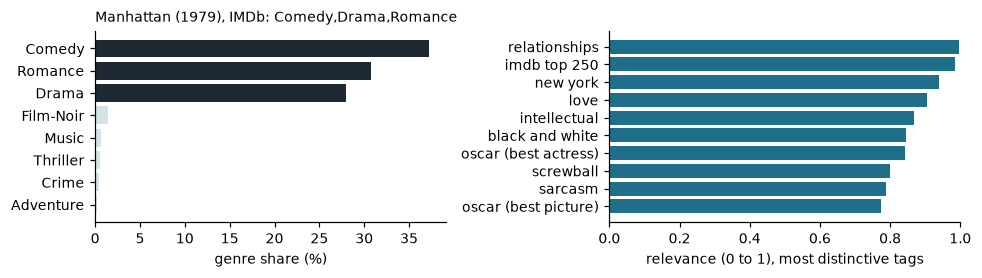

In [3]:
top_tags = pd.read_csv(FEATURES / "tag_top.csv")

def show(title):
    hits = films.index[films["primaryTitle"].str.lower() == title.lower()]
    if len(hits) == 0:
        return print("no scored film called", title)
    i = hits[films.loc[hits, "y"].argmax()]          # the latest film with that title
    order = np.argsort(-share[i])[:8][::-1]
    t = top_tags[top_tags["tconst"] == films["tconst"][i]].sort_values("relevance")
    fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.6))
    a.barh([GENRES[j] for j in order], 100 * share[i, order], color=[INK if imdb[i, j] else LIGHT for j in order])
    a.set_xlabel("genre share (%)"); a.set_title(f"{films['primaryTitle'][i]} ({films['y'][i]}), IMDb: {films['genres'][i]}",
                                                 loc="left", fontsize=9)
    b.barh(t["tag"], t["relevance"], color=ACCENT); b.set_xlim(0, 1); b.set_xlabel("relevance (0 to 1), most distinctive tags")
    plt.tight_layout(); plt.show()

for title in ["Nacho Libre", "Alien", "Shaun of the Dead", "Manhattan"]:
    show(title)

## 3. Does it agree with IMDb's genres?

IMDb's labels weren't used to build the scores, so they make a fair test. For each genre we ask how well the
relevance separates the films IMDb gives that genre from the rest. The AUC is the chance that a random film with
the genre scores higher than a random film without it: 1 is perfect and 0.5 is a coin flip. The null shuffles the
IMDb labels across films 200 times and keeps the highest AUC it reached.

,tag,imdb_films,auc,auc_null_max,median_relevance_labelled,median_relevance_unlabelled
Thriller,thriller,990,0.813,0.521,0.437,0.080
Romance,romance,1257,0.831,0.518,0.500,0.091
Drama,drama,3657,0.835,0.519,0.543,0.174
Fantasy,fantasy,507,0.851,0.527,0.503,0.075
Family,kids and family,377,0.881,0.547,0.466,0.038
Mystery,mystery,662,0.881,0.532,0.407,0.038
Crime,crime,1386,0.891,0.524,0.489,0.031
Adventure,adventure,1129,0.905,0.528,0.597,0.118
Sci-Fi,sci-fi,476,0.919,0.532,0.722,0.051
Music,music,218,0.921,0.556,0.809,0.031


mean AUC over the 22 genres 0.925, lowest 0.813
the genre with the largest share is one of the film's IMDb genres for 85.6% of films; with films shuffled 23.4% on average and 24.8% at most
a film's IMDb genres found among its equally many top-share genres: 71.4%


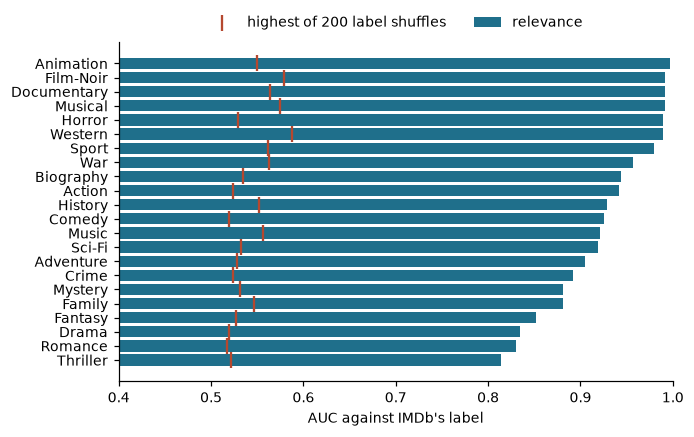

In [4]:
per = pd.DataFrame(checks["imdb_labels"]["per_genre"]).T
tab = per[["tag", "imdb_films", "auc", "auc_null_max",
           "median_relevance_labelled", "median_relevance_unlabelled"]].sort_values("auc")
display(tab.style.format({c: "{:.3f}" for c in tab.columns[2:]}))
il = checks["imdb_labels"]
print(f"mean AUC over the 22 genres {il['auc_mean']:.3f}, lowest {il['auc_min']:.3f}")
print(f"the genre with the largest share is one of the film's IMDb genres for {il['fit']['top_genre_in_imdb']:.1%} of films; "
      f"with films shuffled {il['top_genre_in_imdb_null_mean']:.1%} on average and {il['top_genre_in_imdb_null_max']:.1%} at most")
print(f"a film's IMDb genres found among its equally many top-share genres: {il['fit']['imdb_genres_in_top_k']:.1%}")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(tab.index, tab["auc"], color=ACCENT, label="relevance")
ax.scatter(tab["auc_null_max"], tab.index, marker="|", s=120, color=RED, zorder=3, label="highest of 200 label shuffles")
ax.set_xlim(0.4, 1); ax.set_xlabel("AUC against IMDb's label")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1), ncol=2)
plt.show()

The broad genres at the top of the table score lowest. That is partly IMDb's side of the comparison, because
IMDb lists at most three genres and a film with a love story often has three others listed first. The narrow
genres at the bottom are close to perfect.

## 4. From relevance to a percentage

Relevance isn't a percentage. A film can score 0.9 on both "comedy" and "romance", and a genre that doesn't apply
still scores a little: the last column of the table above is the median relevance among films IMDb doesn't give
the genre, and for Action and Drama it's well above zero. Over 22 genres those leftovers add up, so dividing plain
relevance by its sum spreads a film thinly (first row below). Squaring the relevance first shrinks the leftovers
and leaves the order of the genres as it was.

In [5]:
fit = pd.DataFrame({"relevance / sum": il["fit_power_1"], "relevance squared / sum (used)": il["fit"]}).T
fit.columns = ["top genre is an IMDb genre", "IMDb genres among the top ones", "share that falls on IMDb's genres",
               "effective number of genres (median)"]
display(fit.style.format("{:.3f}"))
print(f"IMDb lists a median of {il['imdb_genre_count_median']:.0f} genres per film")
print(f"median largest share {il['top_share_median']:.1%}; one genre holds over half for {il['top_share_over_half']:.1%} of films")

,top genre is an IMDb genre,IMDb genres among the top ones,share that falls on IMDb's genres,effective number of genres (median)
relevance / sum,0.856,0.714,0.463,9.760
relevance squared / sum (used),0.856,0.714,0.674,4.218


IMDb lists a median of 3 genres per film
median largest share 45.5%; one genre holds over half for 40.9% of films


The effective number of genres is exp(entropy of the shares): 1 if one genre holds everything, 3 if three
split evenly. Squaring brings it much closer to the three genres IMDb lists, and about two thirds of a film's share
then falls on those genres. The power of 2 is our choice. The first two columns don't depend on it, because
squaring keeps the order.

## 5. What the shares add to IMDb's labels

If shares only repeated the labels, every Comedy would have about the same comedy share. They don't. The boxes
show the share of a genre among the films IMDb gives that genre.

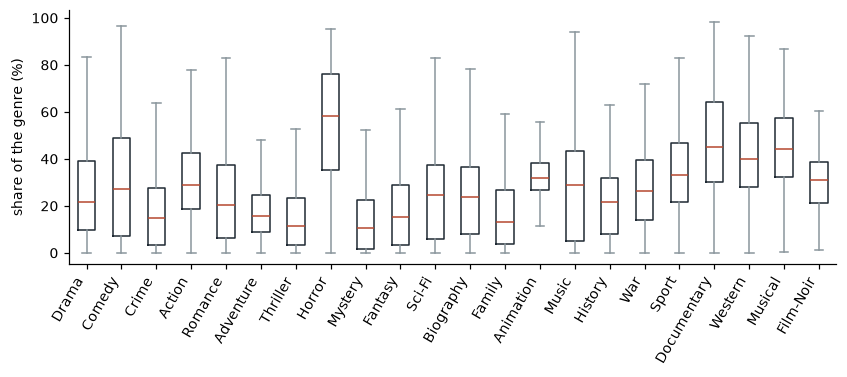

IMDb comedies with the smallest and largest comedy share


,primaryTitle,y,genres,comedy_share
814,My Night at Maud's,1969,"Comedy,Drama,Romance",0.0001
4671,As It Is in Heaven,2004,"Comedy,Drama,Music",0.0001
221,Song of the South,1946,"Animation,Comedy,Family",0.0002
6322,Heartbeats,2010,"Comedy,Drama,Romance",0.0002
302,Early Summer,1951,"Comedy,Drama,Romance",0.0002
4443,Waiting...,2005,Comedy,0.9378
2891,Don't Be a Menace to South Central While Drink...,1996,"Comedy,Crime",0.9382
4088,Ali G Indahouse,2002,Comedy,0.9430
6430,The Campaign,2012,Comedy,0.9555
5500,Step Brothers,2008,Comedy,0.9638


In [6]:
order = [g for g in per.sort_values("imdb_films", ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot([100 * share[imdb[:, GENRES.index(g)], GENRES.index(g)] for g in order], tick_labels=order, showfliers=False,
           medianprops={"color": RED}, boxprops={"color": INK}, whiskerprops={"color": GREY}, capprops={"color": GREY})
ax.set_ylabel("share of the genre (%)"); plt.xticks(rotation=60, ha="right"); plt.show()
j = GENRES.index("Comedy")
c = films[imdb[:, j]].assign(comedy_share=share[imdb[:, j], j]).sort_values("comedy_share")
cols = ["primaryTitle", "y", "genres", "comedy_share"]
print("IMDb comedies with the smallest and largest comedy share")
display(pd.concat([c.head(5)[cols], c.tail(5)[cols]]))

## 6. Two scoring methods

The dataset ships two sets of scores: TagDL, a neural network, and glmer, the regression from the original Tag
Genome paper. They were trained on the same survey, so their agreement shows how much the scores depend on the
model. It can't show that both are right.

We use their mean. Against IMDb's genres the three are close, with the mean slightly ahead on AUC. The bigger
reason is the tags that score 0.5 or more on over half of all films, which can't be telling films apart: TagDL has
many of them, glmer one.

In [7]:
tm = checks["two_methods"]
cmp = pd.DataFrame({
    "mean AUC over genres": {"mean (used)": il["auc_mean"], "TagDL": il["auc_mean_tagdl"], "glmer": il["auc_mean_glmer"]},
    "top genre is an IMDb genre": {"mean (used)": il["fit"]["top_genre_in_imdb"], "TagDL": il["fit_tagdl"]["top_genre_in_imdb"],
                                   "glmer": il["fit_glmer"]["top_genre_in_imdb"]},
    "tags strong on over half of films": {k2: len(checks["tag_baselines"][k]["tags_strong_on_over_half_of_films"])
                                          for k2, k in (("mean (used)", "mean"), ("TagDL", "tagdl"), ("glmer", "glmer"))},
    "strong tags per film (median)": {k2: checks["tag_baselines"][k]["median_strong_tags_per_film"]
                                      for k2, k in (("mean (used)", "mean"), ("TagDL", "tagdl"), ("glmer", "glmer"))},
})
display(cmp.style.format({"mean AUC over genres": "{:.3f}", "top genre is an IMDb genre": "{:.3f}", "strong tags per film (median)": "{:.0f}"}))
print("still strong on over half of films under the mean:", ", ".join(checks["tag_baselines"]["mean"]["tags_strong_on_over_half_of_films"]))
print(f"correlation between the two methods across films, per tag: median {tm['r_per_tag_median']:.3f}, "
      f"10th percentile {tm['r_per_tag_p10']:.3f}, lowest {tm['r_per_tag_min']:.3f} ({tm['r_per_tag_min_tag']})")
print("tags where they correlate below 0.5:", ", ".join(tm["tags_with_r_below_0.5"]))
r = pd.Series(tm["r_per_genre"]).sort_values()
print(f"per genre: lowest {r.index[0]} {r.iloc[0]:.3f}, highest {r.index[-1]} {r.iloc[-1]:.3f}")
print(f"same top genre under both methods for {tm['same_top_genre']:.1%} of films; "
      f"mean absolute difference in a genre share {100 * tm['mean_abs_share_difference']:.1f} points")
same = (films["top_genre_tagdl"] == films["top_genre_glmer"])
print("most common disagreements on the top genre (TagDL, glmer):")
print(films[~same].groupby(["top_genre_tagdl", "top_genre_glmer"]).size().sort_values(ascending=False).head(6).to_string())

,mean AUC over genres,top genre is an IMDb genre,tags strong on over half of films,strong tags per film (median)
mean (used),0.925,0.856,8,64
TagDL,0.914,0.838,21,88
glmer,0.923,0.863,1,46


still strong on over half of films under the mean: catastrophe, creativity, good, great ending, life & death, life philosophy, original, pg-13
correlation between the two methods across films, per tag: median 0.910, 10th percentile 0.741, lowest -0.307 (not funny)
tags where they correlate below 0.5: c.s. lewis, finnish, goretastic, made for tv, no dialogue, not funny, oscar (best music - original score), overrated, remade, simple, space program, truman capote, unfunny
per genre: lowest Thriller 0.874, highest Drama 0.976
same top genre under both methods for 80.5% of films; mean absolute difference in a genre share 1.7 points
most common disagreements on the top genre (TagDL, glmer):
top_genre_tagdl  top_genre_glmer
Drama            Comedy             79
Romance          Comedy             67
Sci-Fi           Action             55
Drama            Romance            51
Biography        Drama              43
Thriller         Action             28


## 7. Against what people said

The survey asked MovieLens users how strongly a tag applies to a film, from 1 (not at all) to 5 (very much). The
scores were trained on these answers, so the agreement below is in-sample. The honest error is the dataset's own
ten-fold test, on the 5-point scale.

38,371 rated film-tag pairs on 4,312 of our films, 3,697 of them on genre tags
mean: Spearman 0.746 over all tags, 0.774 on genre tags
tagdl: Spearman 0.741 over all tags, 0.760 on genre tags
glmer: Spearman 0.732 over all tags, 0.774 on genre tags
held-out mean absolute error on the 1-5 scale: TagDL 0.846, glmer 0.876


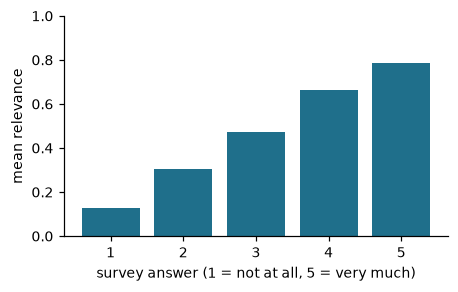

In [8]:
sv = checks["survey"]
print(f"{sv['pairs']:,} rated film-tag pairs on {sv['films']:,} of our films, {sv['genre_pairs']:,} of them on genre tags")
for m in ("mean", "tagdl", "glmer"):
    print(f"{m}: Spearman {sv[m]['spearman']:.3f} over all tags, {sv[m]['spearman_genre_tags']:.3f} on genre tags")
mae = sv["held_out_mae_5_point_scale"]
print(f"held-out mean absolute error on the 1-5 scale: TagDL {mae['tagdl']:.3f}, glmer {mae['glmer']:.3f}")
by = pd.Series(sv["mean"]["mean_score_by_answer"])
fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.bar(by.index, by.values, color=ACCENT)
ax.set_xlabel("survey answer (1 = not at all, 5 = very much)"); ax.set_ylabel("mean relevance"); ax.set_ylim(0, 1)
plt.show()

A held-out error of about 0.85 on a 5-point scale means a single film-tag score is rough. It's about a
fifth of the scale. Read a score as "barely, somewhat or strongly", and trust averages over many films more than
one film's number.

## 8. Any tag

The same matrix answers "which films are most X" for all 1,084 tags, and how common a tag is. The tags at the
top of the common list are the ones from section 6 that score high on nearly every film. Read those as noise,
which is why a film's tag list ranks by distance from the tag's median.

In [9]:
def most(tag, n=8):
    j = tag_col[tag]
    top = np.argsort(-relevance[:, j])[:n]
    return films.loc[top, ["primaryTitle", "y", "genres"]].assign(relevance=relevance[top, j].round(3)).reset_index(drop=True)

for tag in ["time travel", "heist", "based on a true story"]:
    print(tag); display(most(tag))
strong = (relevance >= 0.5).mean(axis=0)
common = pd.Series(strong, index=tags).sort_values(ascending=False)
print("tags that apply strongly (relevance 0.5 or more) to the most films:")
print((100 * common.head(12)).round(1).to_string())
print(f"median tag applies strongly to {100 * np.median(strong):.1f}% of films; "
      f"a film has a median of {int(np.median((relevance >= 0.5).sum(axis=1)))} such tags")

time travel


,primaryTitle,y,genres,relevance
0,Looper,2012,"Action,Drama,Sci-Fi",0.992
1,Frequency,2000,"Crime,Drama,Mystery",0.987
2,Back to the Future,1985,"Adventure,Comedy,Sci-Fi",0.986
3,The Butterfly Effect,2004,"Drama,Sci-Fi,Thriller",0.985
4,Back to the Future Part II,1989,"Adventure,Comedy,Sci-Fi",0.985
5,Star Trek: First Contact,1996,"Action,Adventure,Drama",0.981
6,Frequently Asked Questions About Time Travel,2009,"Comedy,Sci-Fi",0.980
7,Timecrimes,2007,"Horror,Mystery,Sci-Fi",0.979


heist


,primaryTitle,y,genres,relevance
0,Rififi,1955,"Crime,Drama,Thriller",0.997
1,The Killing,1956,"Crime,Drama,Film-Noir",0.993
2,The Good Thief,2002,"Action,Crime,Drama",0.992
3,Ocean's Eleven,2001,"Crime,Thriller",0.992
4,The Score,2001,"Crime,Drama,Thriller",0.992
5,Inside Man,2006,"Crime,Drama,Mystery",0.991
6,The Bank Job,2008,"Crime,Thriller",0.991
7,The Italian Job,2003,"Action,Crime,Thriller",0.991


based on a true story


,primaryTitle,y,genres,relevance
0,Kon-Tiki,2012,"Adventure,Biography,Drama",0.993
1,Glory Road,2006,"Biography,Drama,Sport",0.992
2,Fruitvale Station,2013,"Biography,Crime,Drama",0.991
3,The Dam Busters,1955,"Drama,History,War",0.990
4,Sergeant York,1941,"Biography,Drama,History",0.989
5,Rush,2013,"Biography,Drama,Sport",0.989
6,Cinderella Man,2005,"Biography,Drama,Romance",0.988
7,The Express,2008,"Biography,Drama,Sport",0.988


tags that apply strongly (relevance 0.5 or more) to the most films:
catastrophe        100.0
original           100.0
life philosophy     88.2
pg-13               67.6
creativity          64.3
life & death        63.4
good                58.9
great ending        51.4
happy ending        48.8
good soundtrack     47.3
weird               46.7
dialogue            46.6
median tag applies strongly to 3.3% of films; a film has a median of 64 such tags


## 9. A sample to read

Twenty random films with their three largest shares and five strongest tags, to read against what you know of
the films. The seed is fixed, so the sample is the same on every run.

In [10]:
rng = np.random.default_rng(2805)
rows = []
for i in rng.choice(len(films), 20, replace=False):
    g3 = ", ".join(f"{GENRES[j]} {100 * share[i, j]:.0f}%" for j in np.argsort(-share[i])[:3])
    t5 = ", ".join(top_tags[top_tags["tconst"] == films["tconst"][i]]["tag"].head(5))
    rows.append({"film": f"{films['primaryTitle'][i]} ({films['y'][i]})", "IMDb": films["genres"][i], "top shares": g3, "top tags": t5})
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame(rows))

,film,IMDb,top shares,top tags
0,The Remains of the Day (1993),"Drama,Romance","Drama 51%, Romance 46%, Action 1%","world war ii, 1930s, literature, book was better, england"
1,You Kill Me (2007),"Comedy,Crime,Romance","Crime 34%, Comedy 26%, Drama 20%","alcoholism, serial killer, crime, hitman, assassin"
2,The Hard Way (1991),"Action,Comedy,Crime","Action 39%, Comedy 28%, Adventure 16%","buddy movie, action, comedy, detective, funny"
3,Meet Dave (2008),"Adventure,Comedy,Family","Sci-Fi 37%, Comedy 28%, Action 9%","alien, aliens, space, sci-fi, mars"
4,To Be or Not to Be (1983),"Comedy,Drama,War","Comedy 28%, Drama 19%, Thriller 16%","remake, world war ii, humor, wartime, jews"
5,Iron Man (2008),"Action,Adventure,Sci-Fi","Action 23%, Comedy 18%, Adventure 16%","marvel, comic book adaption, super hero, superhero, vigilante"
6,The Naked City (1948),"Crime,Drama,Film-Noir","Film-Noir 23%, Crime 22%, Drama 19%","noir, detective, crime, train, police"
7,Last Man Standing (1996),"Action,Crime,Drama","Action 43%, Western 32%, Crime 14%","remake, organized crime, guns, gangs, gangster"
8,Layer Cake (2004),"Crime,Drama,Thriller","Crime 35%, Thriller 21%, Drama 21%","gangster, organized crime, caper, stylish, crime"
9,Miami Blues (1990),"Comedy,Crime,Drama","Crime 60%, Thriller 16%, Film-Noir 12%","crime, detective, lyrical, independent film, violence"


## What this measures and what it misses

- **It measures how viewers describe a film.** The scores come from tags, ratings and reviews written after
  release. That suits genre and theme. It doesn't suit predicting profit from tags such as "oscar (best picture)",
  "boring" or "imdb top 250", which record how the film was received.
- **Nothing after 2014.** Coverage by decade is in section 1. The clean sample since 2010 is mostly missing.
- **Shares depend on two choices of ours**: which 22 tags stand for the genres, and the power of 2. Relevance
  doesn't depend on either, so use relevance when one tag is the question and shares when the mix is.
- **One score is rough**, as section 7 shows, and some tags carry noise: section 6 lists the tags that score high
  on most films and the tags where the two methods disagree.
- **A 22-way split forces a total of 100%.** A film that is strongly five things gets smaller shares than a film
  that is weakly one thing. The `effective_genres` column says how spread out a film is.